# Land Use Classification from Satellite Images Using Deep Learning
**COMP-671 Deep Learning — Final Project** · Yagna Saikumar

**Problem.** Governments and environmental groups need to know how land is used (shrinking forests, growing cities, farmland). Manual checking across large areas is slow and expensive. This notebook trains a model that takes a small satellite image and predicts its land-use class.

**Data.** EuroSAT (RGB): ~27,000 labelled 64×64 Sentinel-2 images, 10 classes.

**Plan.**
1. Load data and make a fixed, saved train/val/test split (70/15/15, stratified)
2. Exploratory data analysis
3. **Baseline:** logistic regression on downsampled pixels
4. **CNN** trained from scratch
5. **Controlled comparison:** CNN *with* vs *without* data augmentation (everything else identical)
6. Evaluation: accuracy, macro F1, confusion matrix, failure analysis
7. Inference demo on unseen images

**Success criteria.** Primary metric: test macro-F1. A meaningful result is a CNN that beats the pixel baseline by ≥ 15 points and reaches ≥ 90 % test accuracy. Augmentation counts as helping if it raises macro-F1 by more than ~0.5 points.

## 1. Setup & configuration

In [1]:
import os, json, random, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets, transforms
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
from tqdm.auto import tqdm

SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False
set_seed()
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
DATA_DIR, RESULTS_DIR, MODELS_DIR = 'data', 'results', 'models'
for d in (DATA_DIR, RESULTS_DIR, MODELS_DIR): os.makedirs(d, exist_ok=True)
print('Device:', DEVICE)

Device: cuda


In [2]:
# All key hyperparameters in one place (copied into the README)
CONFIG = dict(seed=SEED, split='70/15/15 stratified', batch_size=128, epochs=25, lr=1e-3,
              weight_decay=1e-4, optimizer='Adam', scheduler='CosineAnnealing', dropout=0.3,
              baseline='LogReg on 16x16 RGB pixels', augmentation='hflip+vflip+rot90')
json.dump(CONFIG, open(f'{RESULTS_DIR}/config.json', 'w'), indent=2); CONFIG

{'seed': 42,
 'split': '70/15/15 stratified',
 'batch_size': 128,
 'epochs': 25,
 'lr': 0.001,
 'weight_decay': 0.0001,
 'optimizer': 'Adam',
 'scheduler': 'CosineAnnealing',
 'dropout': 0.3,
 'baseline': 'LogReg on 16x16 RGB pixels',
 'augmentation': 'hflip+vflip+rot90'}

## 2. Load EuroSAT and create a reproducible split
The split indices are saved to `results/splits.json` so anyone can repeat the experiments exactly.

In [3]:
full = datasets.EuroSAT(root=DATA_DIR, download=True)   # ~90 MB
CLASSES = full.classes
labels = np.array(full.targets)
print(len(full), 'images |', len(CLASSES), 'classes:', CLASSES)

split_path = os.path.join(RESULTS_DIR, 'splits.json')
if os.path.exists(split_path):
    splits = json.load(open(split_path))
else:
    idx = np.arange(len(full))
    tr, tmp = train_test_split(idx, test_size=0.30, stratify=labels, random_state=SEED)
    va, te = train_test_split(tmp, test_size=0.50, stratify=labels[tmp], random_state=SEED)
    splits = {'train': tr.tolist(), 'val': va.tolist(), 'test': te.tolist()}
    json.dump(splits, open(split_path, 'w'))
print({k: len(v) for k, v in splits.items()})

100%|██████████| 94.3M/94.3M [00:01<00:00, 87.1MB/s]


27000 images | 10 classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
{'train': 18900, 'val': 4050, 'test': 4050}


## 3. Exploratory data analysis
EuroSAT is roughly balanced (2,000–3,000 images per class), which is why **macro-F1** (every class weighted equally) is reported next to accuracy.

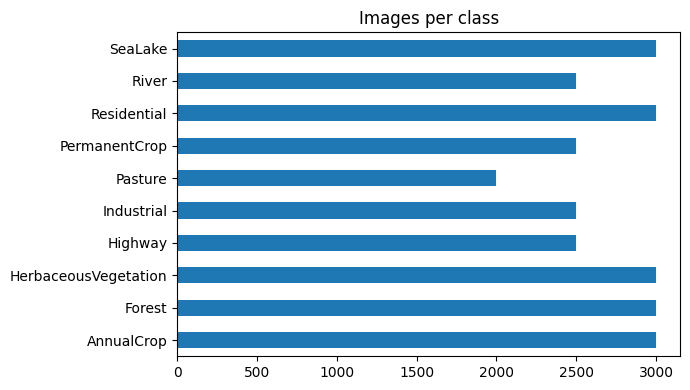

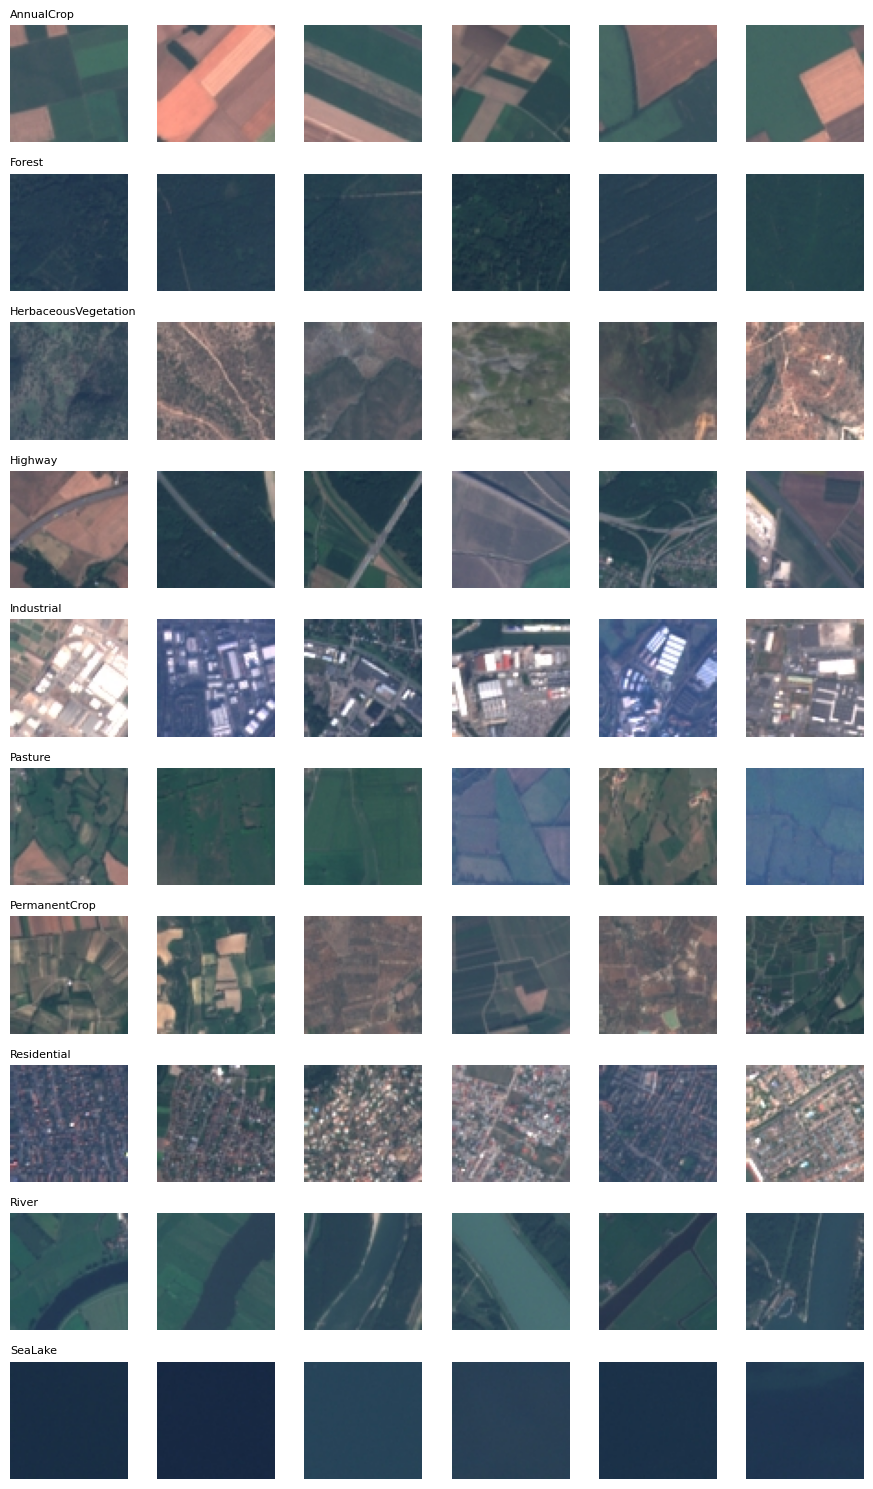

In [4]:
counts = pd.Series(labels).map(dict(enumerate(CLASSES))).value_counts().reindex(CLASSES)
counts.plot.barh(figsize=(7,4), title='Images per class'); plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/class_distribution.png'); plt.show()

fig, axes = plt.subplots(len(CLASSES), 6, figsize=(9, 15))
for c in range(len(CLASSES)):
    ids = np.random.choice(np.where(labels == c)[0], 6, replace=False)
    for j, i in enumerate(ids):
        axes[c, j].imshow(full[i][0]); axes[c, j].axis('off')
    axes[c, 0].set_title(CLASSES[c], fontsize=8, loc='left')
plt.tight_layout(); plt.savefig(f'{RESULTS_DIR}/samples.png'); plt.show()

In [5]:
# Per-channel mean/std from the TRAINING split only (no test leakage)
to_t = transforms.ToTensor()
X = torch.stack([to_t(full[i][0]) for i in splits['train'][:5000]])
MEAN, STD = X.mean((0,2,3)).tolist(), X.std((0,2,3)).tolist()
print('mean', np.round(MEAN,3), 'std', np.round(STD,3))

mean [0.346 0.382 0.409] std [0.203 0.137 0.116]


## 4. Data pipelines
Two training transforms: **plain** (normalize only) and **augmented** (flips + 90° rotations — valid for overhead imagery, since there is no 'up' in a satellite view). Val/test are never augmented.

In [6]:
class Wrap(Dataset):
    def __init__(self, base, ids, tf): self.base, self.ids, self.tf = base, ids, tf
    def __len__(self): return len(self.ids)
    def __getitem__(self, i):
        img, y = self.base[self.ids[i]]; return self.tf(img), y

norm = transforms.Normalize(MEAN, STD)
TF_PLAIN = transforms.Compose([transforms.ToTensor(), norm])
class Rot90:
    def __call__(self, x): return torch.rot90(x, random.randint(0,3), (1,2))
TF_AUG = transforms.Compose([transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(),
                             transforms.ToTensor(), Rot90(), norm])

BATCH = CONFIG['batch_size']
def loaders(train_tf):
    g = torch.Generator().manual_seed(SEED)
    return (DataLoader(Wrap(full, splits['train'], train_tf), BATCH, shuffle=True, num_workers=0, generator=g),
            DataLoader(Wrap(full, splits['val'],  TF_PLAIN), BATCH, num_workers=0),
            DataLoader(Wrap(full, splits['test'], TF_PLAIN), BATCH, num_workers=0))

## 5. Baseline: logistic regression on pixels
Images downsampled to 16×16×3 = 768 features. If the CNN cannot clearly beat this, deep learning is not justified.

In [7]:
def pixel_features(ids, size=16):
    tf = transforms.Compose([transforms.Resize(size), transforms.ToTensor()])
    return np.stack([tf(full[i][0]).flatten().numpy() for i in tqdm(ids)]), labels[ids]

Xtr, ytr = pixel_features(splits['train']); Xte, yte = pixel_features(splits['test'])
mu, sd = Xtr.mean(0), Xtr.std(0) + 1e-6
t0 = time.time()
base = LogisticRegression(max_iter=2000, C=1.0).fit((Xtr-mu)/sd, ytr)
pred_base = base.predict((Xte-mu)/sd)
RESULTS = {'Baseline (LogReg)': {'acc': accuracy_score(yte, pred_base),
                                 'f1': f1_score(yte, pred_base, average='macro')}}
print(RESULTS, f'{time.time()-t0:.0f}s')

  0%|          | 0/18900 [00:00<?, ?it/s]

  0%|          | 0/4050 [00:00<?, ?it/s]

{'Baseline (LogReg)': {'acc': 0.44666666666666666, 'f1': 0.4386814751683872}} 285s


## 6. CNN architecture
Four conv blocks (Conv→BatchNorm→ReLU ×2, then max-pool), global average pooling, dropout, linear head. Loss: cross-entropy (classes are roughly balanced, so no weighting). Optimizer: Adam with cosine learning-rate decay. Model selection: best validation macro-F1.

In [8]:
def block(i, o):
    return nn.Sequential(nn.Conv2d(i,o,3,padding=1), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
                         nn.Conv2d(o,o,3,padding=1), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
                         nn.MaxPool2d(2))
class LandCNN(nn.Module):
    def __init__(self, n=10):
        super().__init__()
        self.features = nn.Sequential(block(3,32), block(32,64), block(64,128), block(128,256))  # 64→4
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(256, n))
    def forward(self, x): return self.head(self.features(x))
print(f'{sum(p.numel() for p in LandCNN().parameters()):,} parameters')

1,176,746 parameters


## 7. Training and evaluation helpers

In [9]:
@torch.no_grad()
def predict(model, dl):
    model.eval(); P, Y = [], []
    for x, y in dl:
        P.append(model(x.to(DEVICE)).argmax(1).cpu()); Y.append(y)
    return torch.cat(Y).numpy(), torch.cat(P).numpy()

def train(name, train_tf, epochs=CONFIG['epochs'], lr=CONFIG['lr']):
    set_seed()                                   # identical init for fair comparison
    tr_dl, va_dl, te_dl = loaders(train_tf)
    model = LandCNN(len(CLASSES)).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=CONFIG['weight_decay'])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)
    hist, best = [], -1
    for ep in range(epochs):
        model.train(); tot, n = 0, 0
        for x, y in tqdm(tr_dl, leave=False, desc=f'{name} ep{ep+1}'):
            x, y = x.to(DEVICE), y.to(DEVICE)
            loss = F.cross_entropy(model(x), y)
            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item()*len(y); n += len(y)
        sched.step()
        yv, pv = predict(model, va_dl)
        f1 = f1_score(yv, pv, average='macro')
        hist.append({'epoch': ep+1, 'train_loss': tot/n, 'val_acc': accuracy_score(yv, pv), 'val_f1': f1})
        print(f"ep{ep+1:02d} loss {tot/n:.4f} | val acc {hist[-1]['val_acc']:.4f} f1 {f1:.4f}")
        if f1 > best:
            best = f1; torch.save(model.state_dict(), f'{MODELS_DIR}/{name}.pth')
    model.load_state_dict(torch.load(f'{MODELS_DIR}/{name}.pth'))
    yt, pt = predict(model, te_dl)
    RESULTS[name] = {'acc': accuracy_score(yt, pt), 'f1': f1_score(yt, pt, average='macro')}
    pd.DataFrame(hist).to_csv(f'{RESULTS_DIR}/{name}_history.csv', index=False)
    return model, pd.DataFrame(hist), yt, pt

## 8. Train CNN — no augmentation

In [10]:
cnn_plain, h_plain, yt, pt_plain = train('CNN_plain', TF_PLAIN)

CNN_plain ep1:   0%|          | 0/148 [00:00<?, ?it/s]

ep01 loss 0.8413 | val acc 0.7726 f1 0.7655


CNN_plain ep2:   0%|          | 0/148 [00:00<?, ?it/s]

ep02 loss 0.5048 | val acc 0.8101 f1 0.7883


CNN_plain ep3:   0%|          | 0/148 [00:00<?, ?it/s]

...

ep23 loss 0.0280 | val acc 0.9686 f1 0.9677


CNN_plain ep24:   0%|          | 0/148 [00:00<?, ?it/s]

ep24 loss 0.0260 | val acc 0.9704 f1 0.9695


CNN_plain ep25:   0%|          | 0/148 [00:00<?, ?it/s]

ep25 loss 0.0244 | val acc 0.9699 f1 0.9690


## 9. Controlled comparison — CNN with augmentation
Only the training transform changes. Architecture, seed, split, optimizer, epochs and learning rate are identical.

In [11]:
cnn_aug, h_aug, yt, pt_aug = train('CNN_aug', TF_AUG)

CNN_aug ep1:   0%|          | 0/148 [00:00<?, ?it/s]

ep01 loss 0.8332 | val acc 0.7889 f1 0.7734


CNN_aug ep2:   0%|          | 0/148 [00:00<?, ?it/s]

ep02 loss 0.5223 | val acc 0.8020 f1 0.7958


CNN_aug ep3:   0%|          | 0/148 [00:00<?, ?it/s]

...

ep23 loss 0.0655 | val acc 0.9689 f1 0.9682


CNN_aug ep24:   0%|          | 0/148 [00:00<?, ?it/s]

ep24 loss 0.0615 | val acc 0.9706 f1 0.9698


CNN_aug ep25:   0%|          | 0/148 [00:00<?, ?it/s]

ep25 loss 0.0601 | val acc 0.9721 f1 0.9713


## 10. Results

,Test accuracy,Test macro-F1
Baseline (LogReg),0.4467,0.4387
CNN_plain,0.9726,0.9718
CNN_aug,0.9798,0.9792


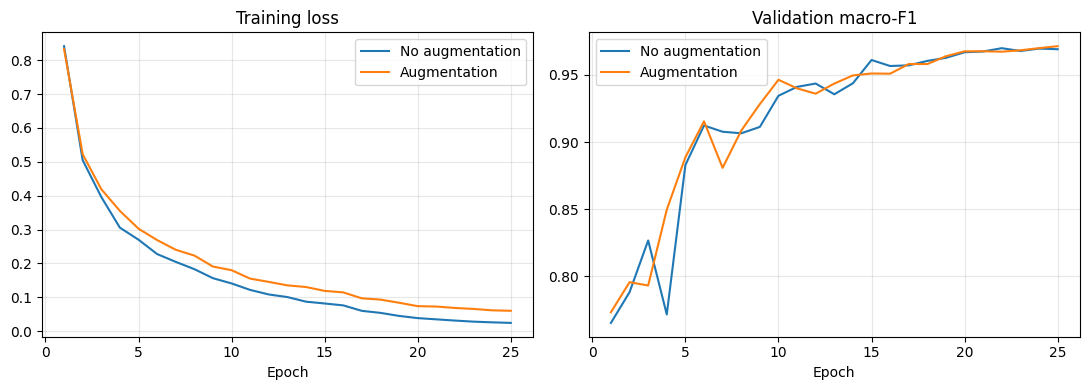

In [12]:
res = pd.DataFrame(RESULTS).T.rename(columns={'acc':'Test accuracy','f1':'Test macro-F1'}).round(4)
res.to_csv(f'{RESULTS_DIR}/results_summary.csv'); display(res)

fig, ax = plt.subplots(1, 2, figsize=(11,4))
for h, lbl in [(h_plain,'No augmentation'), (h_aug,'Augmentation')]:
    ax[0].plot(h.epoch, h.train_loss, label=lbl); ax[1].plot(h.epoch, h.val_f1, label=lbl)
ax[0].set(title='Training loss', xlabel='Epoch'); ax[1].set(title='Validation macro-F1', xlabel='Epoch')
for a in ax: a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f'{RESULTS_DIR}/learning_curves.png'); plt.show()

Best model: CNN_aug 

                      precision    recall  f1-score   support

          AnnualCrop      0.943     0.964     0.954       450
              Forest      0.989     1.000     0.994       450
HerbaceousVegetation      0.973     0.976     0.974       450
             Highway      0.984     0.981     0.983       375
          Industrial      0.982     0.995     0.988       375
             Pasture      0.973     0.963     0.968       300
       PermanentCrop      0.963     0.960     0.961       375
         Residential      1.000     0.991     0.996       450
               River      0.989     0.963     0.976       375
             SeaLake      1.000     0.996     0.998       450

            accuracy                          0.980      4050
           macro avg      0.980     0.979     0.979      4050
        weighted avg      0.980     0.980     0.980      4050



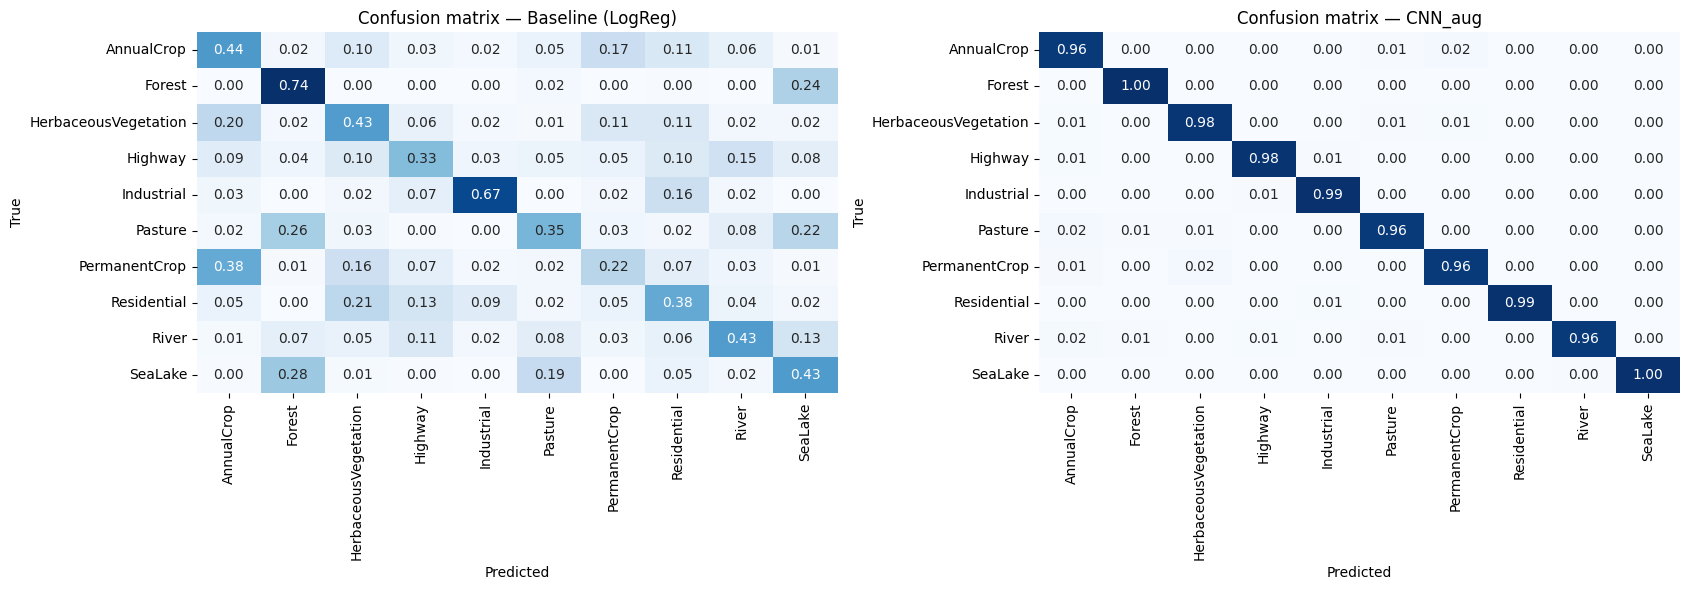

In [13]:
best_name = max(['CNN_plain','CNN_aug'], key=lambda k: RESULTS[k]['f1'])
best_pred = pt_aug if best_name == 'CNN_aug' else pt_plain
print('Best model:', best_name, '\n')
print(classification_report(yt, best_pred, target_names=CLASSES, digits=3))

fig, ax = plt.subplots(1, 2, figsize=(17,6))
for a, p, t in [(ax[0], pred_base, 'Baseline (LogReg)'), (ax[1], best_pred, best_name)]:
    cm = confusion_matrix(yt, p, normalize='true')
    sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES, ax=a, cbar=False)
    a.set(title=f'Confusion matrix — {t}', xlabel='Predicted', ylabel='True')
plt.tight_layout(); plt.savefig(f'{RESULTS_DIR}/confusion_matrices.png'); plt.show()

## 11. Failure analysis — what does the model get wrong?

Most common confusions (true -> predicted):
  AnnualCrop             -> PermanentCrop          9
  PermanentCrop          -> HerbaceousVegetation   8
  River                  -> AnnualCrop             7
  Pasture                -> AnnualCrop             7
  PermanentCrop          -> AnnualCrop             5


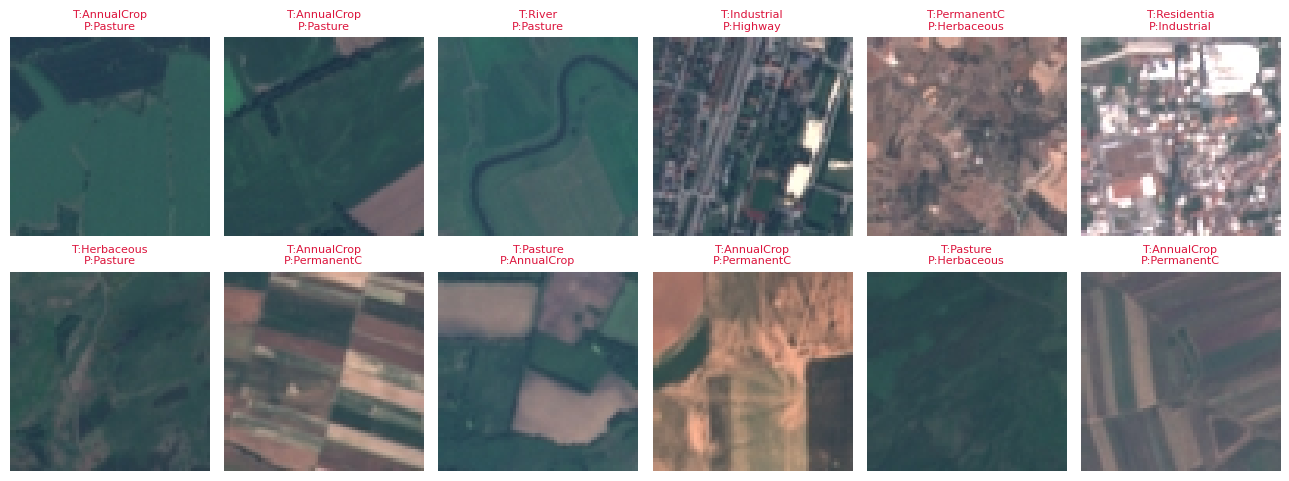

In [14]:
test_ids = np.array(splits['test']); wrong = np.where(best_pred != yt)[0]
cm = confusion_matrix(yt, best_pred); np.fill_diagonal(cm, 0)
top = np.dstack(np.unravel_index(np.argsort(cm.ravel())[::-1][:5], cm.shape))[0]
print('Most common confusions (true -> predicted):')
for t, p in top: print(f'  {CLASSES[t]:22s} -> {CLASSES[p]:22s} {cm[t,p]}')

sel = np.random.choice(wrong, min(12, len(wrong)), replace=False)
fig, axes = plt.subplots(2, 6, figsize=(13,5))
for a, i in zip(axes.ravel(), sel):
    a.imshow(full[test_ids[i]][0]); a.axis('off')
    a.set_title(f'T:{CLASSES[yt[i]][:10]}\nP:{CLASSES[best_pred[i]][:10]}', fontsize=8, color='crimson')
plt.tight_layout(); plt.savefig(f'{RESULTS_DIR}/misclassified.png'); plt.show()

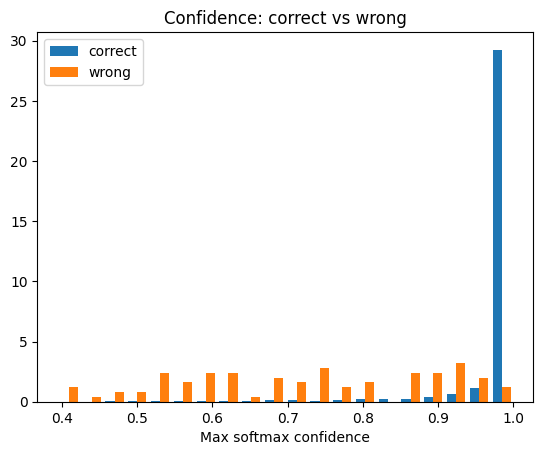

Per-class F1 (worst first):
AnnualCrop              0.954
PermanentCrop           0.961
Pasture                 0.968
HerbaceousVegetation    0.974
River                   0.976
Highway                 0.983
Industrial              0.988
Forest                  0.994
Residential             0.996
SeaLake                 0.998
dtype: float64


In [15]:
# Where is the model uncertain? Confidence of correct vs wrong predictions
best_model = cnn_aug if best_name == 'CNN_aug' else cnn_plain
_, _, te_dl = loaders(TF_PLAIN); best_model.eval(); conf = []
with torch.no_grad():
    for x, _ in te_dl: conf.append(F.softmax(best_model(x.to(DEVICE)), 1).max(1).values.cpu())
conf = torch.cat(conf).numpy(); ok = best_pred == yt
plt.hist([conf[ok], conf[~ok]], bins=20, label=['correct','wrong'], density=True)
plt.legend(); plt.xlabel('Max softmax confidence'); plt.title('Confidence: correct vs wrong')
plt.savefig(f'{RESULTS_DIR}/confidence.png'); plt.show()
per_class = pd.Series(f1_score(yt, best_pred, average=None), index=CLASSES).sort_values()
print('Per-class F1 (worst first):'); print(per_class.round(3))

## 12. Inference demo
Load the saved weights from disk (as a user would) and classify test images the model never trained on.

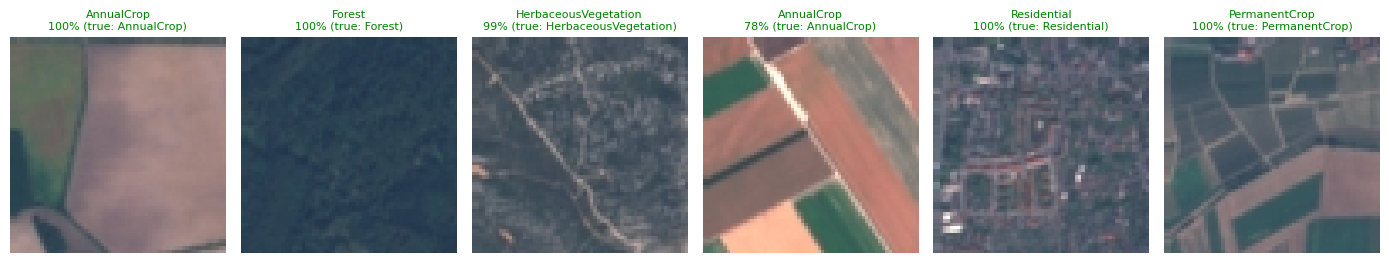

In [16]:
def classify(img, model_path=f'{MODELS_DIR}/{best_name}.pth'):
    m = LandCNN(len(CLASSES)).to(DEVICE); m.load_state_dict(torch.load(model_path, map_location=DEVICE)); m.eval()
    with torch.no_grad():
        p = F.softmax(m(TF_PLAIN(img).unsqueeze(0).to(DEVICE)), 1)[0].cpu()
    k = p.argmax().item(); return CLASSES[k], p[k].item()

fig, axes = plt.subplots(1, 6, figsize=(14,3))
for a, i in zip(axes, np.random.choice(splits['test'], 6, replace=False)):
    img, y = full[i]; lab, c = classify(img)
    a.imshow(img); a.axis('off')
    a.set_title(f'{lab}\n{c:.0%} (true: {CLASSES[y]})', fontsize=8, color='green' if lab == CLASSES[y] else 'red')
plt.tight_layout(); plt.savefig(f'{RESULTS_DIR}/inference_demo.png'); plt.show()

## 13. Conclusions
*(Single-run numbers are from Section 10 (seed 42); the 3-seed robustness check is in Section 14.)*

* **CNN vs baseline:** The CNN reaches **98.0 %** test accuracy (macro-F1 0.979) vs **44.7 %** (macro-F1 0.439) for logistic regression on pixels, a gain of **53 points**. Spatial feature learning is essential; raw pixel colour alone is not enough. The result is close to the ~98 % reported in the original EuroSAT paper, which supports the correctness of the pipeline.
* **Controlled comparison (augmentation):** Over 3 seeds, augmentation raised macro-F1 from **0.9727 ± 0.0020 to 0.9781 ± 0.0015**, a mean gain of **+0.53 points**, and it was better in **3 out of 3 seeds** (+0.36, +0.50, +0.74). This meets the 0.5-point threshold set in advance, so the gain is small but consistent. The learning curves show why: both models reach a similar validation F1 (~0.969–0.971), but the final training loss is **0.024 without augmentation vs 0.060 with it**, so the plain model memorizes the training set more. Augmentation acts as a **regularizer**, and its run-to-run spread is also slightly lower.
* **Errors:** The most confused classes are the agricultural ones: **AnnualCrop → PermanentCrop** (9), **PermanentCrop → HerbaceousVegetation** (8) and **Pasture → AnnualCrop** (7). These are the lowest-F1 classes (AnnualCrop 0.954, PermanentCrop 0.961, Pasture 0.968) and look alike from above as green fields with row texture; separating them needs seasonal (multi-date) imagery or near-infrared bands. Narrow **River** images are sometimes predicted as AnnualCrop (7) because the river covers few pixels among farmland. Forest, Residential and SeaLake are near-perfect (F1 ≥ 0.994).
* **Limitations:** Only RGB bands (Sentinel-2 has 13), 10 classes, 3 seeds, and a random split (nearby images may appear in both train and test). All images come from Europe, so performance on other regions is not tested.
* **Ethics:** Land-use maps influence zoning, farm subsidies and environmental enforcement; the model's weakest classes are crop types, so errors could misdirect agricultural funding. Sentinel-2 at 10 m/pixel cannot identify individuals, so privacy risk is low. Outputs should support, not replace, human review.
* **Future work:** Use all 13 spectral bands (especially near-infrared for crop types), try transfer learning (e.g. ResNet-18), and test on a geographically held-out region.

## 14. Robustness check — augmentation comparison over 3 seeds
A single run cannot show whether a gap of under one point is real or noise. Both models are retrained with seeds 1 and 2 (the seed-42 runs above are reused), keeping everything else identical: data split, architecture, optimizer, learning rate and epochs. Test results are reported as mean ± standard deviation, and the per-seed gain shows whether augmentation wins consistently.

In [17]:
def train_seed(name, train_tf, seed, epochs=CONFIG['epochs'], lr=CONFIG['lr']):
    set_seed(seed)
    g = torch.Generator().manual_seed(seed)
    tr_dl = DataLoader(Wrap(full, splits['train'], train_tf), BATCH, shuffle=True, num_workers=0, generator=g)
    va_dl = DataLoader(Wrap(full, splits['val'], TF_PLAIN), BATCH, num_workers=0)
    te_dl = DataLoader(Wrap(full, splits['test'], TF_PLAIN), BATCH, num_workers=0)
    model = LandCNN(len(CLASSES)).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=CONFIG['weight_decay'])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)
    best, path = -1, f'{MODELS_DIR}/{name}_s{seed}.pth'
    for ep in range(epochs):
        model.train()
        for x, y in tr_dl:
            x, y = x.to(DEVICE), y.to(DEVICE)
            loss = F.cross_entropy(model(x), y); opt.zero_grad(); loss.backward(); opt.step()
        sched.step()
        yv, pv = predict(model, va_dl); f1 = f1_score(yv, pv, average='macro')
        if f1 > best: best = f1; torch.save(model.state_dict(), path)
    model.load_state_dict(torch.load(path, map_location=DEVICE))
    yt, pt = predict(model, te_dl)
    return accuracy_score(yt, pt), f1_score(yt, pt, average='macro')

rows = [{'model': 'CNN_plain', 'seed': 42, 'acc': RESULTS['CNN_plain']['acc'], 'f1': RESULTS['CNN_plain']['f1']},
        {'model': 'CNN_aug',   'seed': 42, 'acc': RESULTS['CNN_aug']['acc'],   'f1': RESULTS['CNN_aug']['f1']}]
for seed in [1, 2]:
    for name, tf in [('CNN_plain', TF_PLAIN), ('CNN_aug', TF_AUG)]:
        t0 = time.time(); acc, f1 = train_seed(name, tf, seed)
        rows.append({'model': name, 'seed': seed, 'acc': acc, 'f1': f1})
        print(f'{name} seed {seed}: acc {acc:.4f} f1 {f1:.4f} ({time.time()-t0:.0f}s)')

ms = pd.DataFrame(rows); ms.to_csv(f'{RESULTS_DIR}/multiseed_runs.csv', index=False)
summary = ms.groupby('model')[['acc', 'f1']].agg(['mean', 'std']).round(4)
summary.to_csv(f'{RESULTS_DIR}/multiseed_summary.csv'); display(summary)
diff = ms.pivot(index='seed', columns='model', values='f1'); diff['gain'] = diff['CNN_aug'] - diff['CNN_plain']
print('\nPer-seed macro-F1 gain from augmentation:'); print(diff.round(4))
print(f"Mean gain: {diff['gain'].mean()*100:+.2f} points, augmentation better in {(diff['gain']>0).sum()}/3 seeds")

CNN_plain seed 1: acc 0.9758 f1 0.9751 (388s)
CNN_aug seed 1: acc 0.9790 f1 0.9786 (426s)
CNN_plain seed 2: acc 0.9723 f1 0.9714 (390s)
CNN_aug seed 2: acc 0.9773 f1 0.9764 (430s)


acc              f1        
             mean     std    mean     std
model                                    
CNN_aug    0.9787  0.0013  0.9781  0.0015
CNN_plain  0.9736  0.0019  0.9727  0.0020


Per-seed macro-F1 gain from augmentation:
model  CNN_aug  CNN_plain    gain
seed                             
1       0.9786     0.9751  0.0036
2       0.9764     0.9714  0.0050
42      0.9792     0.9718  0.0074
Mean gain: +0.53 points, augmentation better in 3/3 seeds
